In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
# Load dataset
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
!ls /content/drive/

MyDrive


In [4]:
file_path = "/content/drive/MyDrive/2025-Y2-S1-MLB-B8G1-03/results/outputs/student_depression_after_outlier_removal.csv"
df = pd.read_csv(file_path)

In [5]:
df.head()

,Age,CGPA,Suicidal_Thoughts,Study_Hours,Family_History,Depression,Gender_Male,Gender_Female,Diet_Healthy,Diet_Moderate,Diet_Unhealthy
0,33,8.97,1,3,0,1,1,0,1,0,0
1,24,5.90,0,3,1,0,0,1,0,1,0
2,31,7.03,0,9,1,0,1,0,1,0,0
3,28,5.59,1,4,1,1,0,1,0,1,0
4,25,8.13,1,1,0,0,0,1,0,1,0


In [6]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, MinMaxScaler

## Keep original copy for comparison
df_before = df.copy()

# Define numerical columns
numerical_cols = df.select_dtypes(include=np.number).columns.tolist()

# Initialize MinMaxScaler
minmax_scaler = MinMaxScaler()


# Apply Min-Max Scaling (create a new df_normalized)
df_normalized = df.copy()
df_normalized[numerical_cols] = minmax_scaler.fit_transform(df[numerical_cols])

#print normalized dataset
print("\nDataset after Min-Max Normalization:")
print(df_normalized.head())


Dataset after Min-Max Normalization:
    Age      CGPA  Suicidal_Thoughts  Study_Hours  Family_History  Depression  \
0  0.60  0.792757                1.0     0.250000             0.0         1.0   
1  0.24  0.175050                0.0     0.250000             1.0         0.0   
2  0.52  0.402414                0.0     0.750000             1.0         0.0   
3  0.40  0.112676                1.0     0.333333             1.0         1.0   
4  0.28  0.623742                1.0     0.083333             0.0         0.0   

   Gender_Male  Gender_Female  Diet_Healthy  Diet_Moderate  Diet_Unhealthy  
0          1.0            0.0           1.0            0.0             0.0  
1          0.0            1.0           0.0            1.0             0.0  
2          1.0            0.0           1.0            0.0             0.0  
3          0.0            1.0           0.0            1.0             0.0  
4          0.0            1.0           0.0            1.0             0.0  


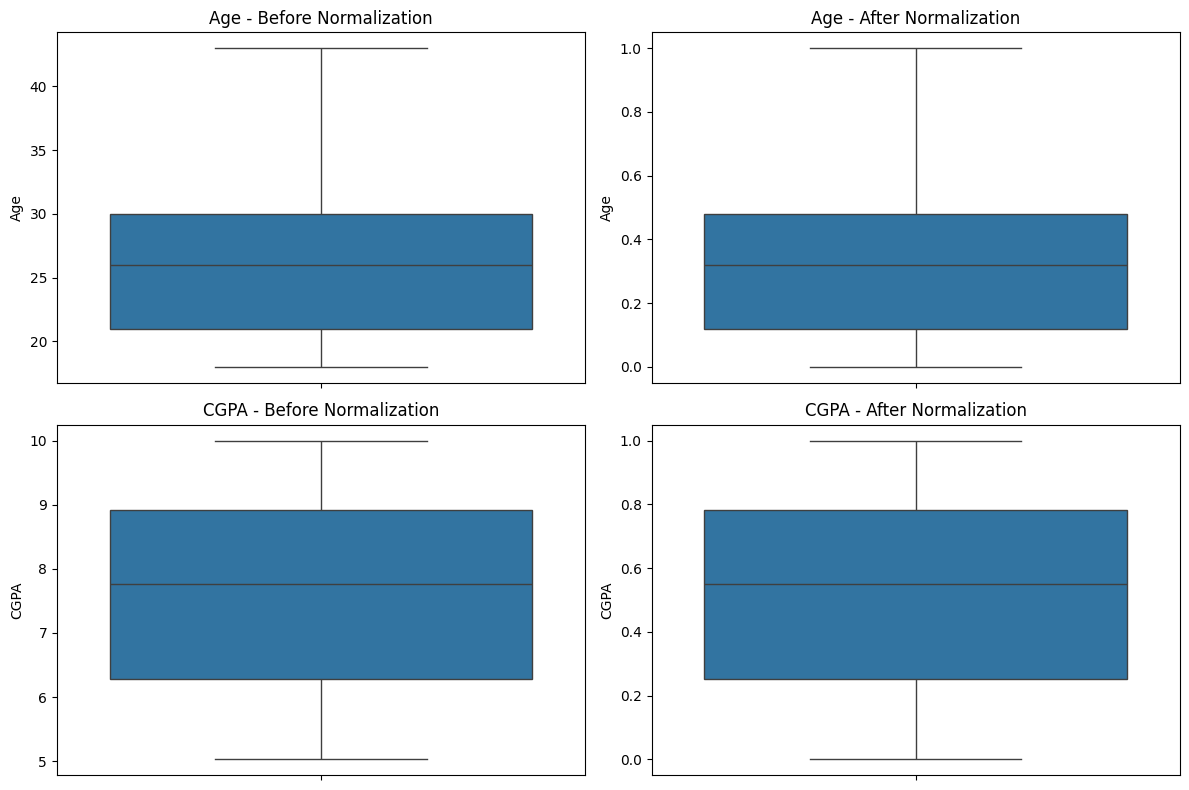

Saved and displayed: /content/drive/MyDrive/2025-Y2-S1-MLB-B8G1-03/results/eda_visualizations/boxplots_before_after_normalization.png


In [7]:
#plots for normalization
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Age before normalization (using original data)
sns.boxplot(y=df["Age"], ax=axes[0,0])
axes[0,0].set_title("Age - Before Normalization")

# Age after normalization (using normalized data)
sns.boxplot(y=df_normalized["Age"], ax=axes[0,1])  # Changed to normalized data
axes[0,1].set_title("Age - After Normalization")

# CGPA before normalization (using original data)
sns.boxplot(y=df["CGPA"], ax=axes[1,0])
axes[1,0].set_title("CGPA - Before Normalization")

# CGPA after normalization (using normalized data)
sns.boxplot(y=df_normalized["CGPA"], ax=axes[1,1])  # Changed to normalized data
axes[1,1].set_title("CGPA - After Normalization")

plt.tight_layout()

# Save and show
save_path = "/content/drive/MyDrive/2025-Y2-S1-MLB-B8G1-03/results/eda_visualizations/boxplots_before_after_normalization.png"
plt.savefig(save_path, bbox_inches="tight", dpi=300)  # Added dpi for better quality
plt.show()

print(f"Saved and displayed: {save_path}")

In [8]:
# Save processed dataset / features
# Define save path for processed dataset
save_path = "/content/drive/MyDrive/2025-Y2-S1-MLB-B8G1-03/results/outputs/student_depression_after_normalization.csv"

# Save as CSV
df_normalized.to_csv(save_path, index=False)